Total Training Sentences: 80
Number of Intents: 8

Vocabulary Size: 117
Maximum Sequence Length: 6
Input Shape: (80, 6)

Training Samples: 51
Validation Samples: 13
Testing Samples: 16

GRU Chatbot Architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 6, 32)          │         3,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        18,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           264 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,904 (97.28 KB)

 Trainable params: 24,904 (97.28 KB)

 Non-trainable params: 0 (0.00 B)


Training GRU Chatbot...
Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 79ms/step - accuracy: 0.0588 - loss: 2.0805 - val_accuracy: 0.1538 - val_loss: 2.0753
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.1373 - loss: 2.0728 - val_accuracy: 0.1538 - val_loss: 2.0731
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.3529 - loss: 2.0635 - val_accuracy: 0.1538 - val_loss: 2.0694
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.3137 - loss: 2.0558 - val_accuracy: 0.2308 - val_loss: 2.0616
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.5882 - loss: 2.0375 - val_accuracy: 0.3077 - val_loss: 2.0549
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5490 - loss: 2.0261 - val_accuracy: 0.3846 - val_loss: 2.0425
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6667 - loss: 1.9982 - val_accuracy: 0.3077 - val_loss: 2.0253
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7255 - loss: 1.9507 - val_acc

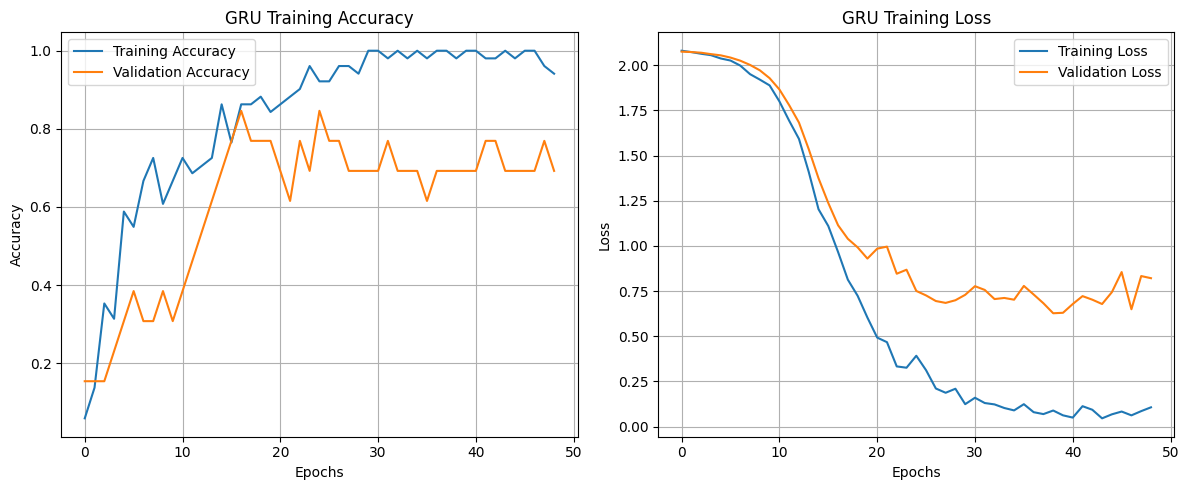


FINAL RESULT
Total Intents: 8
Vocabulary Size: 117
GRU Units: 64
Optimizer: Adam
Loss Function: Sparse Categorical Crossentropy
Test Accuracy: 62.5 %

GRU Chatbot Completed Successfully!


In [ ]:
# DLL Experiment - GRU Based Chatbot Application

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import random

from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report


# 1. Prepare Chatbot Dataset
intents = {

    "greeting": [
        "hello",
        "hi",
        "hey",
        "good morning",
        "good evening",
        "hello there",
        "hi there",
        "how are you",
        "hey bot",
        "good afternoon"
    ],

    "goodbye": [
        "bye",
        "goodbye",
        "see you later",
        "talk to you later",
        "see you",
        "have a nice day",
        "i am leaving",
        "good night",
        "catch you later",
        "exit"
    ],

    "thanks": [
        "thank you",
        "thanks",
        "thanks a lot",
        "many thanks",
        "i appreciate it",
        "that was helpful",
        "thank you so much",
        "great thanks",
        "much appreciated",
        "you helped me"
    ],

    "bot_identity": [
        "what is your name",
        "who are you",
        "tell me your name",
        "are you a chatbot",
        "what should i call you",
        "introduce yourself",
        "who am i talking to",
        "what are you",
        "your name please",
        "identify yourself"
    ],

    "deep_learning": [
        "what is deep learning",
        "explain machine learning",
        "what is artificial intelligence",
        "tell me about neural networks",
        "what is a neural network",
        "define deep learning",
        "what is an ai model",
        "explain data science",
        "what is supervised learning",
        "what is a dataset"
    ],

    "gru": [
        "what is gru",
        "explain gru network",
        "what is a gated recurrent unit",
        "difference between rnn and gru",
        "why use gru",
        "how does gru work",
        "tell me about recurrent networks",
        "what are update and reset gates",
        "gru in deep learning",
        "explain recurrent neural network"
    ],

    "exam": [
        "when is my practical exam",
        "how to prepare for practical",
        "give me viva questions",
        "what should i study for viva",
        "how do i prepare for exam",
        "tell me exam tips",
        "help me revise deep learning",
        "what is a practical exam",
        "how to study neural networks",
        "give practical preparation tips"
    ],

    "help": [
        "can you help me",
        "i need help",
        "help me with this",
        "i have a question",
        "please guide me",
        "i am confused",
        "what can you do",
        "assist me",
        "i need assistance",
        "can you explain this"
    ]
}


# 2. Prepare Response Dictionary
responses = {

    "greeting": [
        "Hello! How can I help you today?",
        "Hi! Nice to meet you.",
        "Hey! What would you like to know?"
    ],

    "goodbye": [
        "Goodbye! Have a nice day.",
        "See you later!",
        "Bye! Take care."
    ],

    "thanks": [
        "You're welcome!",
        "Happy to help!",
        "Glad I could help you."
    ],

    "bot_identity": [
        "I am a GRU-based chatbot.",
        "I am an intelligent chatbot application.",
        "I am a chatbot designed using deep learning."
    ],

    "deep_learning": [
        "Deep learning uses neural networks with multiple layers to learn patterns.",
        "Deep learning is a part of machine learning.",
        "Neural networks are the foundation of deep learning."
    ],

    "gru": [
        "GRU stands for Gated Recurrent Unit.",
        "GRU uses reset and update gates to process sequential information.",
        "GRU is a type of recurrent neural network."
    ],

    "exam": [
        "Understand the concepts and practice your programs.",
        "Revise the architecture, activation functions and optimizers.",
        "Practice coding and prepare important viva questions."
    ],

    "help": [
        "Sure! What would you like help with?",
        "I am here to assist you.",
        "Please tell me your question."
    ]
}


# 3. Convert Text into Training Data
texts = []
labels = []

intent_names = list(intents.keys())

for intent_index, intent in enumerate(intent_names):

    for sentence in intents[intent]:

        texts.append(sentence)

        labels.append(intent_index)


labels = np.array(labels)

print("Total Training Sentences:", len(texts))
print("Number of Intents:", len(intent_names))


# 4. Tokenization
tokenizer = Tokenizer(
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(texts)

sequences = tokenizer.texts_to_sequences(texts)

vocab_size = len(tokenizer.word_index) + 1

max_length = max(
    len(sequence) for sequence in sequences
)

# Padding
X = pad_sequences(
    sequences,
    maxlen=max_length,
    padding="post"
)

Y = labels

print("\nVocabulary Size:", vocab_size)
print("Maximum Sequence Length:", max_length)
print("Input Shape:", X.shape)


# 5. Split Dataset
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

X_train, X_val, Y_train, Y_val = train_test_split(
    X_train, Y_train,
    test_size=0.2,
    random_state=42,
    stratify=Y_train
)

print("\nTraining Samples:", len(X_train))
print("Validation Samples:", len(X_val))
print("Testing Samples:", len(X_test))


# 6. Build GRU Model
model = models.Sequential([

    layers.Input(shape=(max_length,)),

    # Word Embedding
    layers.Embedding(
        input_dim=vocab_size,
        output_dim=32,
        mask_zero=True
    ),

    # GRU Layer
    layers.GRU(
        64,
        activation="tanh"
    ),

    # Dense Layer
    layers.Dense(
        32,
        activation="relu"
    ),

    # Dropout
    layers.Dropout(0.3),

    # Output Layer
    layers.Dense(
        len(intent_names),
        activation="softmax"
    )
])


# 7. Compile Model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nGRU Chatbot Architecture:")

model.summary()


# 8. Train GRU Model
print("\nTraining GRU Chatbot...")

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    Y_train,
    validation_data=(X_val, Y_val),
    epochs=100,
    batch_size=8,
    callbacks=[early_stop],
    verbose=1
)

print("\nGRU Chatbot Training Completed!")


# 9. Evaluate Model
test_loss, test_accuracy = model.evaluate(
    X_test,
    Y_test,
    verbose=0
)

print("\n================================")
print("MODEL PERFORMANCE")
print("================================")

print("Test Loss:", round(test_loss, 4))

print(
    "Test Accuracy:",
    round(test_accuracy * 100, 2),
    "%"
)


# 10. Classification Report
predictions = model.predict(
    X_test,
    verbose=0
)

predicted_labels = np.argmax(
    predictions,
    axis=1
)

print("\nClassification Report:")

print(
    classification_report(
        Y_test,
        predicted_labels,
        labels=np.arange(len(intent_names)),
        target_names=intent_names,
        zero_division=0
    )
)


# 11. Chatbot Response Function
def chatbot_response(sentence):

    sentence = sentence.lower().strip()

    sequence = tokenizer.texts_to_sequences(
        [sentence]
    )

    # Check unknown input
    if not sequence[0] or all(
        token == tokenizer.word_index["<OOV>"]
        for token in sequence[0]
    ):

        return "Sorry, I could not understand your message.", "unknown", 0.0

    padded = pad_sequences(
        sequence,
        maxlen=max_length,
        padding="post"
    )

    prediction = model.predict(
        padded,
        verbose=0
    )[0]

    predicted_index = int(np.argmax(prediction))

    confidence = float(prediction[predicted_index])

    predicted_intent = intent_names[predicted_index]

    # Confidence threshold
    if confidence < 0.40:

        return "Sorry, I could not understand your message.", "unknown", confidence

    # Select suitable response
    response = random.choice(
        responses[predicted_intent]
    )

    return response, predicted_intent, confidence


# 12. Random Test Conversation
test_index = np.random.randint(
    0, len(X_test)
)

test_sentence = texts[
    train_test_split(
        np.arange(len(texts)),
        test_size=0.2,
        random_state=42,
        stratify=labels
    )[1][test_index]
]

# Generate Chatbot Response
response, predicted_intent, confidence = chatbot_response(
    test_sentence
)


print("\n================================")
print("CHATBOT CONVERSATION")
print("================================")

print("\nUser:", test_sentence)

print("Predicted Intent:", predicted_intent)

print("Confidence:", round(confidence * 100, 2), "%")

print("\nChatbot:", response)


# 13. Plot Training Accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("GRU Training Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)


# 14. Plot Training Loss
plt.subplot(1, 2, 2)

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("GRU Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# 15. Final Result
print("\n================================")
print("FINAL RESULT")
print("================================")

print("Total Intents:", len(intent_names))

print("Vocabulary Size:", vocab_size)

print("GRU Units: 64")

print("Optimizer: Adam")

print("Loss Function: Sparse Categorical Crossentropy")

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

print("\nGRU Chatbot Completed Successfully!")